# TP3 - Scoring du risque réseau selon la criticité des actifs

**Dataset :** NF-UNSW-NB15 enrichi par un contexte de criticité illustratif.  
**Modèles :** XGBoost Regressor et NGBoost.  
**Cible :** score de risque entre 0 et 100.

Le dataset ne contient pas de criticité métier ni de CMDB. La criticité ajoutée ci-dessous est une **hypothèse pédagogique**, définie **par adresse IP de destination**, à valider et remplacer par les niveaux réels de l'organisation avant tout usage opérationnel.

## 1. Environnement expérimental

Le notebook utilise un échantillon stratifié maximal de 100 000 flux pour limiter le temps de NGBoost. Le split est 70 % apprentissage et 30 % test ; les deux modèles sont évalués sur le même test. Graine aléatoire : 42.

In [ ]:
# Installe les bibliothèques manquantes (Colab/Jupyter avec accès à pip).
import importlib.util, subprocess, sys
for package, module in [("scikit-learn", "sklearn"), ("xgboost", "xgboost"), ("ngboost", "ngboost")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import zipfile, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix
from xgboost import XGBRegressor
from ngboost import NGBRegressor
from ngboost.distns import Normal
from ngboost.scores import LogScore

RANDOM_STATE = 42

# Style commun des graphiques
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
COL_XGB, COL_NGB, COL_REF = "#2F6DB5", "#E69F00", "#555555"

## 2. Charger et explorer le dataset

Le CSV est lu directement depuis le ZIP. Le notebook cherche l'archive à plusieurs endroits (Drive, dossier courant, `/content`) ; sinon Colab demande de la téléverser.

In [ ]:
ZIP_NAMES = ["88695f0f620eb568_MOHANAD_A4706.zip", "88695f0f620eb568_MOHANAD_A4706_1.zip"]
DRIVE_DIR = Path("/content/drive/MyDrive/Colab Notebooks/TPs IA - cybersecurité - 26-27/TP1/datasets")
candidates = ([DRIVE_DIR / n for n in ZIP_NAMES] + [Path(n) for n in ZIP_NAMES]
              + [Path("/content") / n for n in ZIP_NAMES] + [Path("/mnt/user-data/uploads") / n for n in ZIP_NAMES])
ZIP_PATH = next((p for p in candidates if p.exists()), None)
if ZIP_PATH is None:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception:
        pass
    ZIP_PATH = next((p for p in candidates if p.exists()), None)
if ZIP_PATH is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        ZIP_PATH = Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError("ZIP introuvable : place l'archive à côté du notebook ou modifie ZIP_PATH.")

with zipfile.ZipFile(ZIP_PATH) as z:
    CSV_IN_ZIP = next(n for n in z.namelist() if n.endswith("NF-UNSW-NB15.csv"))
    with z.open(CSV_IN_ZIP) as f:
        df = pd.read_csv(f, low_memory=False)
df.columns = df.columns.astype(str).str.strip()
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip()

print("Dimensions :", df.shape)
print()
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print()
print("Doublons exacts :", int(df.duplicated().sum()))
print()
print("Répartition de Label (%) :")
display((100 * df["Label"].value_counts(normalize=True).sort_index()).round(2).to_frame())
print()
print("Aperçu du tableau :")
display(df.head())

Saving 88695f0f620eb568_MOHANAD_A4706.zip to 88695f0f620eb568_MOHANAD_A4706.zip
Dimensions : (1623118, 14)

Valeurs manquantes : 0

Doublons exacts : 19740

Répartition de Label (%) :


,proportion
Label,
0,95.54
1,4.46



Aperçu du tableau :


,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,OUT_BYTES,IN_PKTS,OUT_PKTS,TCP_FLAGS,FLOW_DURATION_MILLISECONDS,Label,Attack
0,149.171.126.0,62073,59.166.0.5,56082,6,0.0,9672,416,11,8,25,15,0,Benign
1,149.171.126.2,32284,59.166.0.5,1526,6,0.0,1776,104,6,2,25,0,0,Benign
2,149.171.126.0,21,59.166.0.1,21971,6,1.0,1842,1236,26,22,25,1111,0,Benign
3,59.166.0.1,23800,149.171.126.0,46893,6,0.0,528,8824,10,12,27,124,0,Benign
4,59.166.0.5,63062,149.171.126.2,21,6,1.0,1786,2340,32,34,25,1459,0,Benign


### Comment lire le chargement et l'exploration ?

La cellule affiche la taille du dataset, le nombre de valeurs manquantes et de doublons, la répartition de `Label` et un aperçu des flux. Chaque ligne représente un flux réseau agrégé. Les doublons sont supprimés plus loin. Environ 95,5 % des flux sont normaux et 4,5 % sont des attaques : le jeu est très déséquilibré.

## 3. Caractéristiques liées à la probabilité d'attaque

Les prédicteurs réseau sont les ports source/destination, les protocoles, les drapeaux TCP, les volumes en octets, le nombre de paquets et la durée du flux. `IPV4_DST_ADDR` sert uniquement à rechercher la criticité. Les adresses IP brutes, `Label` et `Attack` sont exclues de X pour éviter la mémorisation des hôtes et la fuite de cible. Les taux par protocole et par port ci-dessous servent à explorer les associations, pas à prouver une causalité.

In [ ]:
print("Taux d'attaque par protocole (>= 100 flux) :")
proto_rate = df.groupby("PROTOCOL")["Label"].agg(taux_attaque="mean", effectif="size")
display(proto_rate[proto_rate.effectif >= 100].sort_values("taux_attaque", ascending=False).head(10))
print()
print("Taux d'attaque par port destination (>= 100 flux) :")
port_rate = df.groupby("L4_DST_PORT")["Label"].agg(taux_attaque="mean", effectif="size")
display(port_rate[port_rate.effectif >= 100].sort_values("taux_attaque", ascending=False).head(10))

Taux d'attaque par protocole (>= 100 flux) :


,taux_attaque,effectif
PROTOCOL,,
2,0.850877,114
89,0.469526,1772
1,0.456461,712
6,0.041753,1165868
17,0.027036,444110



Taux d'attaque par port destination (>= 100 flux) :


,taux_attaque,effectif
L4_DST_PORT,,
67,0.991870,123
389,0.969925,133
110,0.956209,1530
5060,0.941077,594
139,0.937500,288
443,0.930233,129
8080,0.930000,400
23,0.916667,156
0,0.896552,13079


### Interprétation des taux par protocole et port

Les tableaux montrent, pour les protocoles et ports destination présents au moins 100 fois, la proportion de flux étiquetés comme attaques (`taux_attaque`) et leur effectif (`effectif`). Il faut lire les deux colonnes ensemble : un taux élevé calculé sur peu de flux est moins stable. Cette analyse montre des associations dans ce dataset, pas une causalité.

## 4. Ajouter la criticité de l'actif visé

La criticité (1 = faible, 5 = vitale) est une **hypothèse de scénario**, définie **par adresse IP de destination**.

Pourquoi par IP et non par préfixe ? Avec une criticité par préfixe de réseau, 99,7 % des flux tombent dans le même niveau (5), et toutes les attaques aussi : le score ne prendrait que les valeurs 0 et 100, et la criticité n'apporterait aucune information. Ici, les 20 serveurs `149.171.126.0` à `149.171.126.19` reçoivent des niveaux différents :

- `.0` à `.9` : serveurs très sollicités, jamais attaqués dans ce fichier, criticité répartie de 1 à 5 ;
- `.10` à `.19` : serveurs visés par les attaques, criticité 5, 5, 4, 4, 3, 3, 2, 2, 1, 1 ;
- autres réseaux : criticité par préfixe (`10.40.*` = 5, `175.45.176` = 4, `192.168.241` = 3, `59.166.0` = 2, multicast/loopback = 1).

Cette table n'est pas observée dans les données. Elle doit être remplacée par une CMDB réelle avant tout usage opérationnel.

In [ ]:
# Criticité par IP destination (HYPOTHÈSE pédagogique)
CRITICALITY_BY_IP = {}
for i in range(10):                      # 149.171.126.0 - .9 : jamais attaqués dans ce fichier
    CRITICALITY_BY_IP[f"149.171.126.{i}"] = i % 5 + 1
for i, level in zip(range(10, 20), [5, 5, 4, 4, 3, 3, 2, 2, 1, 1]):   # 149.171.126.10 - .19 : serveurs visés
    CRITICALITY_BY_IP[f"149.171.126.{i}"] = level

CRITICALITY_BY_PREFIX = {
    "10.40.182": 5, "10.40.198": 5, "175.45.176": 4,
    "192.168.241": 3, "59.166.0": 2, "224.0.0": 1, "127.0.0": 1
}

def prefix3(ip):
    return ".".join(str(ip).split(".")[:3])

def criticality(ip):
    if ip in CRITICALITY_BY_IP:
        return CRITICALITY_BY_IP[ip]
    return CRITICALITY_BY_PREFIX.get(prefix3(ip), 1)

df["Asset_Criticality"] = df["IPV4_DST_ADDR"].map(criticality).astype(int)
unknown = sorted({ip for ip in df["IPV4_DST_ADDR"].unique()
                  if ip not in CRITICALITY_BY_IP and prefix3(ip) not in CRITICALITY_BY_PREFIX})

crit_table = df.groupby("Asset_Criticality").agg(
    Hotes=("IPV4_DST_ADDR", "nunique"), Flux=("Label", "size"), Attaques=("Label", "sum"))
crit_table["Taux d'attaque (%)"] = (100 * crit_table["Attaques"] / crit_table["Flux"]).round(2)
print("Répartition des flux par niveau de criticité :")
display(crit_table)
print()
print("IP/préfixes non renseignés (valeur par défaut 1) :", unknown)

Répartition des flux par niveau de criticité :


,Hotes,Flux,Attaques,Taux d'attaque (%)
Asset_Criticality,,,,
1,6,325762,12719,3.90
2,14,329244,17362,5.27
3,6,321990,13273,4.12
4,8,322075,13898,4.32
5,6,324047,15154,4.68



IP/préfixes non renseignés (valeur par défaut 1) : []


### Interprétation de la criticité

Chaque adresse de destination reçoit une criticité de 1 à 5. Le tableau donne, pour chaque niveau, le nombre d'hôtes, de flux et d'attaques. Si le scénario est bien construit, **chaque niveau contient des attaques** (sinon le score ne pourrait jamais prendre certaines valeurs) et le taux d'attaque ne dépend pas trop du niveau (sinon la criticité révélerait directement `Label`). La criticité reste une hypothèse : le dataset ne fournit ni CMDB ni niveau métier réel.

## 5. Construire la cible de risque entre 0 et 100

**Score attendu = 100 × Label × Asset_Criticality / 5.** Un flux normal reçoit 0. Une attaque reçoit un score proportionnel à la criticité : les niveaux 1 à 5 donnent respectivement 20, 40, 60, 80 et 100.

La cible représente la sévérité observée selon ce scénario, pas une probabilité calibrée. Le régresseur apprend le score moyen attendu à partir des seules caractéristiques disponibles au moment du tri d'alertes.

In [ ]:
df = df.replace([np.inf, -np.inf], np.nan).drop_duplicates().copy()
df["Label"] = pd.to_numeric(df["Label"], errors="coerce")
df = df.dropna(subset=["Label", "Asset_Criticality"]).copy()
df["Label"] = df["Label"].astype(int)
df["Risk_Score"] = (100 * df["Label"] * df["Asset_Criticality"] / 5).clip(0, 100)

print("Lignes après nettoyage :", f"{len(df):,}")
print()
print("Bornes du score :", df.Risk_Score.min(), "à", df.Risk_Score.max())
print()
print("Répartition du score de risque :")
score_counts = df.Risk_Score.value_counts().sort_index().rename("Effectif").to_frame()
score_counts["Part (%)"] = (100 * score_counts["Effectif"] / len(df)).round(2)
display(score_counts)

Lignes après nettoyage : 1,603,378

Bornes du score : 0.0 à 100.0

Répartition du score de risque :


,Effectif,Part (%)
Risk_Score,,
0.0,1531166,95.50
20.0,12694,0.79
40.0,17334,1.08
60.0,13259,0.83
80.0,13826,0.86
100.0,15099,0.94


### Interprétation du nettoyage et de la cible

Le nombre de lignes après nettoyage est inférieur au nombre initial à cause des doublons supprimés. `Risk_Score` est borné entre 0 et 100 : un flux normal reçoit 0 ; une attaque reçoit 20, 40, 60, 80 ou 100 selon la criticité de l'actif visé. La cible mesure la sévérité selon la règle choisie ; ce n'est pas une probabilité d'attaque calibrée. La grande majorité des lignes a un score de 0 (trafic normal).

## 6. Prétraiter et séparer apprentissage/test

`PROTOCOL`, `L7_PROTO` et `TCP_FLAGS` sont encodés en one-hot. Le préprocesseur est ajusté sur l'apprentissage seulement. `Asset_Criticality` reste une caractéristique ; les IP brutes, `Label` et `Attack` sont exclues de X.

In [ ]:
TARGET = "Risk_Score"
CAT = ["PROTOCOL", "L7_PROTO", "TCP_FLAGS"]
EXCLUDE = ["Label", "Attack", "IPV4_SRC_ADDR", "IPV4_DST_ADDR", TARGET]
FEATURES = [c for c in df.columns if c not in EXCLUDE]
X, y = df[FEATURES].copy(), df[TARGET].astype(float)
valid = X.notna().all(axis=1) & y.notna()
X, y = X.loc[valid], y.loc[valid]

MAX_SAMPLE = 100_000
if len(X) > MAX_SAMPLE:
    X_sample, _, y_sample, _ = train_test_split(
        X, y, train_size=MAX_SAMPLE, stratify=df.loc[X.index, "Label"], random_state=RANDOM_STATE)
else:
    X_sample, y_sample = X, y
X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample, test_size=0.30,
    stratify=df.loc[X_sample.index, "Label"], random_state=RANDOM_STATE)

cat_cols = [c for c in CAT if c in X_train.columns]
prep = ColumnTransformer(
    [("categorical", OneHotEncoder(handle_unknown="ignore"), cat_cols)],
    remainder="passthrough", sparse_threshold=1.0)
X_train_enc = prep.fit_transform(X_train)
X_test_enc = prep.transform(X_test)
feature_names = prep.get_feature_names_out()

print("Variables retenues :", FEATURES)
print()
print("Taille sample / train / test :", len(X_sample), len(X_train), len(X_test))
print()
print("Nombre de caractéristiques encodées :", X_train_enc.shape[1])

Variables retenues : ['L4_SRC_PORT', 'L4_DST_PORT', 'PROTOCOL', 'L7_PROTO', 'IN_BYTES', 'OUT_BYTES', 'IN_PKTS', 'OUT_PKTS', 'TCP_FLAGS', 'FLOW_DURATION_MILLISECONDS', 'Asset_Criticality']

Taille sample / train / test : 100000 70000 30000

Nombre de caractéristiques encodées : 344


### Interprétation des variables et du split

La liste affiche les variables utilisées comme entrées. Les IP brutes, `Label` et `Attack` sont exclues pour éviter que le modèle apprenne directement l'identité de l'hôte ou la réponse. `Asset_Criticality` est conservée comme caractéristique. L'échantillon contient au maximum 100 000 flux : 70 % pour l'apprentissage et 30 % pour le test, avec la même proportion d'attaques. Le nombre de variables augmente après One-Hot Encoding car chaque catégorie devient une colonne.

## 7. Entraîner XGBoost Regressor

Paramètres : `n_estimators=350`, `max_depth=6`, `learning_rate=0.05`, `subsample=0.8`, `colsample_bytree=0.8`, `objective="reg:squarederror"`, `tree_method="hist"`, graine 42.

In [ ]:
xgb_reg = XGBRegressor(
    n_estimators=350, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    objective="reg:squarederror", tree_method="hist",
    random_state=RANDOM_STATE, n_jobs=-1)
t0 = time.time()
xgb_reg.fit(X_train_enc, y_train)
fit_time_xgb = time.time() - t0
pred_xgb = np.clip(xgb_reg.predict(X_test_enc), 0, 100)
print("XGBoost Regressor entraîné.")
print()
print(f"Temps d'apprentissage : {fit_time_xgb:.1f} s")

XGBoost Regressor entraîné.

Temps d'apprentissage : 14.6 s


### Interprétation de l'entraînement XGBoost

XGBoost Regressor apprend à prédire une valeur numérique de risque à partir des caractéristiques. Les paramètres indiqués plus haut fixent le nombre et la profondeur des arbres ainsi que la vitesse d'apprentissage. « Entraîné » signifie que le modèle a terminé son ajustement sur les données d'apprentissage. Les prédictions sont ramenées dans [0, 100].

## 8. Entraîner NGBoost

NGBoost prédit une distribution, ce qui permet d'estimer la moyenne et l'incertitude. Paramètres : loi normale (`Normal`), `LogScore`, arbre de base de profondeur 2, `n_estimators=250`, `learning_rate=0.03`, graine 42. La matrice est convertie en format dense pour NGBoost.

In [ ]:
def dense32(M):
    return (M.toarray() if hasattr(M, "toarray") else np.asarray(M)).astype(np.float32)

def dist_mean_std(dist):
    """Moyenne et écart-type de la loi prédite (compatible avec plusieurs versions de ngboost)."""
    try:
        return np.asarray(dist.loc, dtype=float), np.asarray(dist.scale, dtype=float)
    except AttributeError:
        return np.asarray(dist.mean(), dtype=float), np.asarray(dist.std(), dtype=float)

X_train_dense, X_test_dense = dense32(X_train_enc), dense32(X_test_enc)
ngb = NGBRegressor(
    Dist=Normal, Score=LogScore,
    Base=DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE),
    n_estimators=250, learning_rate=0.03,
    random_state=RANDOM_STATE, verbose=False)
t0 = time.time()
ngb.fit(X_train_dense, y_train.to_numpy())
fit_time_ngb = time.time() - t0
ngb_dist = ngb.pred_dist(X_test_dense)
mu_ngb, sigma_ngb = dist_mean_std(ngb_dist)
pred_ngb = np.clip(mu_ngb, 0, 100)
print("NGBoost entraîné.")
print()
print(f"Temps d'apprentissage : {fit_time_ngb:.1f} s")

NGBoost entraîné.

Temps d'apprentissage : 290.8 s


### Interprétation de l'entraînement NGBoost

NGBoost prédit une distribution de scores (ici une loi normale), donc une moyenne et un écart-type par flux. Il est entraîné sur le même jeu d'apprentissage que XGBoost. Attention : la cible est très concentrée sur 0 avec quelques valeurs entre 20 et 100, ce qui est loin d'une loi normale. L'écart-type peut donc être mal calibré et doit être interprété avec prudence.

## 9. Comparer les scores prédits et attendus

MAE mesure l'erreur absolue moyenne ; RMSE pénalise davantage les grosses erreurs ; R² mesure la variance expliquée et peut être négatif si le modèle est moins bon qu'une prédiction constante. Une **référence** (prédire toujours la moyenne du train) est ajoutée pour juger si les modèles apportent vraiment quelque chose.

Métriques sur le jeu de test :


,MAE,RMSE,R2
Modèle,,,
Référence (moyenne),5.2148,14.0050,-0.0000
XGBoost Regressor,1.3010,7.0076,0.7496
NGBoost,2.5294,9.3407,0.5552



Exemples de prédictions (15 flux au hasard) :


,Score attendu,Score XGBoost,Score NGBoost,Erreur abs. XGB,Erreur abs. NGBoost
25764,0.0,0.030000,0.59,0.03,0.59
414019,0.0,0.240000,0.48,0.24,0.48
598494,0.0,0.020000,0.58,0.02,0.58
670783,20.0,12.910000,31.11,7.09,11.11
674926,0.0,0.000000,0.08,0.00,0.08
723643,0.0,0.060000,1.04,0.06,1.04
777602,0.0,0.000000,0.10,0.00,0.10
825562,0.0,0.000000,0.78,0.00,0.78
830637,0.0,0.230000,1.23,0.23,1.23
838995,0.0,0.230000,2.33,0.23,2.33


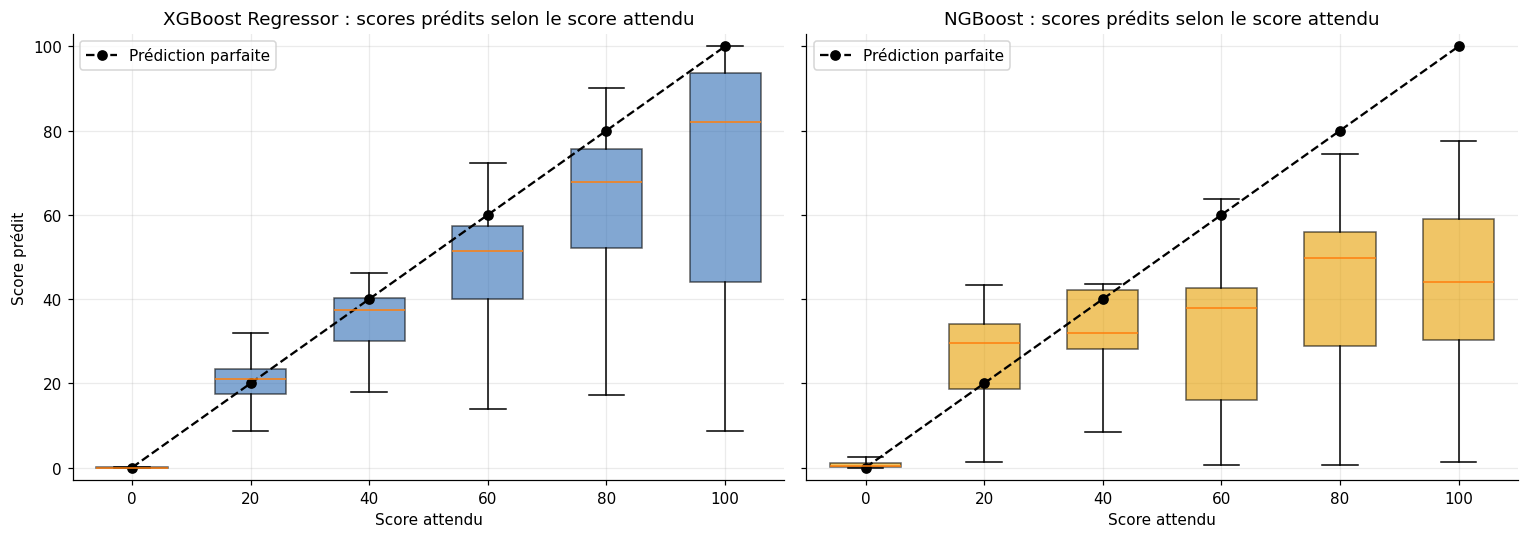

In [ ]:
def score_metrics(name, actual, pred):
    return {"Modèle": name,
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "R2": r2_score(actual, pred)}

baseline = DummyRegressor(strategy="mean").fit(X_train_enc, y_train)
pred_base = baseline.predict(X_test_enc)
metrics = pd.DataFrame([
    score_metrics("Référence (moyenne)", y_test, pred_base),
    score_metrics("XGBoost Regressor", y_test, pred_xgb),
    score_metrics("NGBoost", y_test, pred_ngb)
]).set_index("Modèle")
print("Métriques sur le jeu de test :")
display(metrics.round(4))

compare = pd.DataFrame({
    "Score attendu": y_test,
    "Score XGBoost": pred_xgb,
    "Score NGBoost": pred_ngb,
    "Erreur abs. XGB": np.abs(y_test.to_numpy() - pred_xgb),
    "Erreur abs. NGBoost": np.abs(y_test.to_numpy() - pred_ngb)
}, index=y_test.index)
print()
print("Exemples de prédictions (15 flux au hasard) :")
display(compare.sample(min(15, len(compare)), random_state=RANDOM_STATE).sort_index().round(2))

# Graphique : distribution des scores prédits pour chaque score attendu
expected_values = sorted(y_test.unique())
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, pred, col) in zip(axes, [("XGBoost Regressor", pred_xgb, COL_XGB), ("NGBoost", pred_ngb, COL_NGB)]):
    data = [pred[y_test.to_numpy() == v] for v in expected_values]
    bp = ax.boxplot(data, positions=range(len(expected_values)), widths=0.6, patch_artist=True, showfliers=False)
    for patch in bp["boxes"]:
        patch.set_facecolor(col); patch.set_alpha(0.6)
    ax.plot(range(len(expected_values)), expected_values, color="black", ls="--", marker="o", label="Prédiction parfaite")
    ax.set_xticks(range(len(expected_values)))
    ax.set_xticklabels([str(int(v)) for v in expected_values])
    ax.set_xlabel("Score attendu"); ax.set_ylim(-3, 103)
    ax.set_title(f"{name} : scores prédits selon le score attendu"); ax.legend(loc="upper left")
axes[0].set_ylabel("Score prédit")
plt.tight_layout(); plt.show()

### Comment lire la comparaison ?

Le tableau compare les prédictions au score attendu sur le jeu de test. **MAE** est l'erreur absolue moyenne en points (plus petit = meilleur). **RMSE** pénalise davantage les grandes erreurs (plus petit = meilleur). **R²** mesure la variance expliquée (plus grand = meilleur ; négatif = moins bon qu'une prédiction constante). La ligne « Référence » donne le niveau à battre : un modèle utile doit avoir une MAE et un RMSE inférieurs, et un R² nettement supérieur à 0.

Sur le graphique, chaque boîte montre les scores prédits pour les flux ayant un même score attendu. Plus la boîte est proche de la ligne pointillée, meilleure est la prédiction. Les scores 20 à 100 correspondent à des attaques de criticité croissante, 0 au trafic normal.

## 10. Analyser l'incertitude NGBoost

On construit un intervalle normal approximatif à 90 % : moyenne ± 1,645 × écart-type, borné à [0, 100]. La couverture est la proportion de scores attendus inclus dans cet intervalle ; sa largeur moyenne mesure l'incertitude exprimée en points de risque. On vérifie aussi si l'écart-type est **informatif** : il devrait être plus grand là où l'erreur est plus grande.

Écart-type prédictif moyen : 3.22 points

Couverture observée de l'intervalle 90 % : 97.91%

Largeur moyenne de l'intervalle 90 % : 7.19 points

Corrélation (Spearman) entre écart-type et erreur absolue : 0.896

Couverture selon le score attendu :


,Couverture
0.0,0.993
20.0,0.839
40.0,0.864
60.0,0.635
80.0,0.574
100.0,0.505



Exemples (12 flux au hasard) :


,Attendu,Moyenne NGBoost,Ecart-type,Basse 90%,Haute 90%
825562,0.0,0.78,1.36,0.00,3.02
674926,0.0,0.08,0.53,0.00,0.95
914572,0.0,0.86,1.40,0.00,3.16
777602,0.0,0.10,0.53,0.00,0.97
1427258,0.0,0.58,0.79,0.00,1.88
1161852,0.0,0.00,0.74,0.00,1.22
723643,0.0,1.04,1.07,0.00,2.81
670783,20.0,31.11,11.54,12.13,50.10
414019,0.0,0.48,1.29,0.00,2.60
838995,0.0,2.33,6.29,0.00,12.68


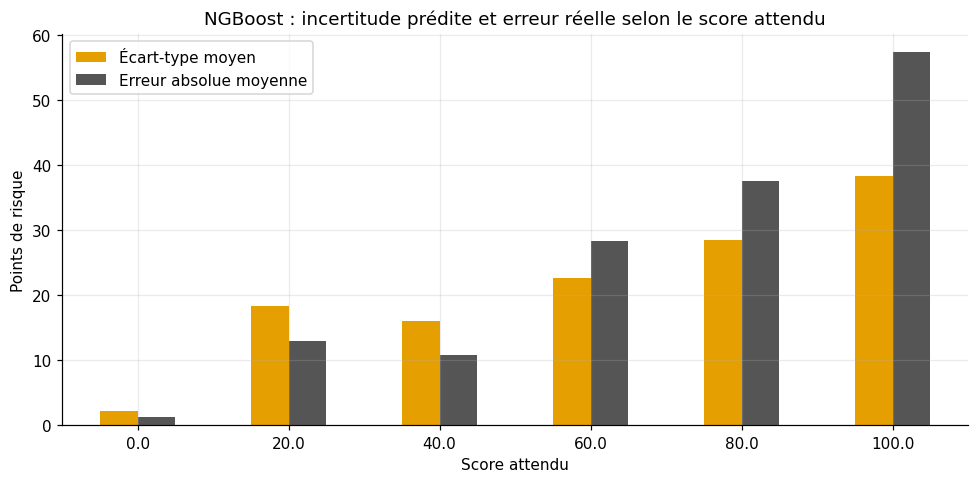

In [ ]:
mu, sigma = mu_ngb, sigma_ngb
lo90 = np.clip(mu - 1.645 * sigma, 0, 100)
hi90 = np.clip(mu + 1.645 * sigma, 0, 100)
actual = y_test.to_numpy()
abs_err = np.abs(actual - np.clip(mu, 0, 100))
inside = (actual >= lo90) & (actual <= hi90)

print(f"Écart-type prédictif moyen : {sigma.mean():.2f} points")
print()
print(f"Couverture observée de l'intervalle 90 % : {inside.mean():.2%}")
print()
print(f"Largeur moyenne de l'intervalle 90 % : {np.mean(hi90 - lo90):.2f} points")
print()
corr = pd.Series(sigma).corr(pd.Series(abs_err), method="spearman")
print(f"Corrélation (Spearman) entre écart-type et erreur absolue : {corr:.3f}")
print()
print("Couverture selon le score attendu :")
display(pd.Series(inside).groupby(actual).mean().rename("Couverture").to_frame().round(3))

uncertainty = pd.DataFrame({"Attendu": actual, "Moyenne NGBoost": np.clip(mu, 0, 100),
                            "Ecart-type": sigma, "Basse 90%": lo90, "Haute 90%": hi90}, index=y_test.index)
print()
print("Exemples (12 flux au hasard) :")
display(uncertainty.sample(min(12, len(uncertainty)), random_state=RANDOM_STATE).round(2))

# Graphique : l'incertitude suit-elle l'erreur ?
by_score = pd.DataFrame({"Score attendu": actual, "Écart-type moyen": sigma,
                         "Erreur absolue moyenne": abs_err}).groupby("Score attendu").mean()
by_score.plot(kind="bar", figsize=(9, 4.5), color=[COL_NGB, COL_REF], rot=0)
plt.title("NGBoost : incertitude prédite et erreur réelle selon le score attendu")
plt.ylabel("Points de risque"); plt.tight_layout(); plt.show()

### Interprétation de l'incertitude NGBoost

L'écart-type moyen résume l'incertitude prédictive en points de risque. L'intervalle à 90 % est construit autour de la moyenne puis borné entre 0 et 100. La couverture indique la part des scores attendus comprise dans cet intervalle ; elle est comparée à la valeur théorique de 90 %. Une couverture élevée avec des intervalles très larges ne signifie pas des prédictions précises.

La corrélation de Spearman et le graphique indiquent si l'incertitude est **utile** : si l'écart-type est plus grand là où l'erreur est plus grande, il peut servir à déclencher une revue humaine. Comme la cible n'est pas normale (beaucoup de 0 et quelques valeurs hautes), la couverture peut être très différente selon le score attendu.

## 11. Niveaux de risque

Seuils proposés : faible [0, 25), moyen [25, 50), élevé [50, 75), critique [75, 100]. Avec les scores attendus 0, 20, 40, 60, 80 et 100 : 0 et 20 → faible, 40 → moyen, 60 → élevé, 80 et 100 → critique.

Nombre de flux par niveau :


,Attendu,XGBoost,NGBoost
Faible,28891,28771,28604
Moyen,324,618,1054
Élevé,219,338,338
Critique,566,273,4



Qualité de la classification en niveaux :


,XGBoost,NGBoost
Niveau exact,0.9757,0.9537
À un niveau près,0.9917,0.9853


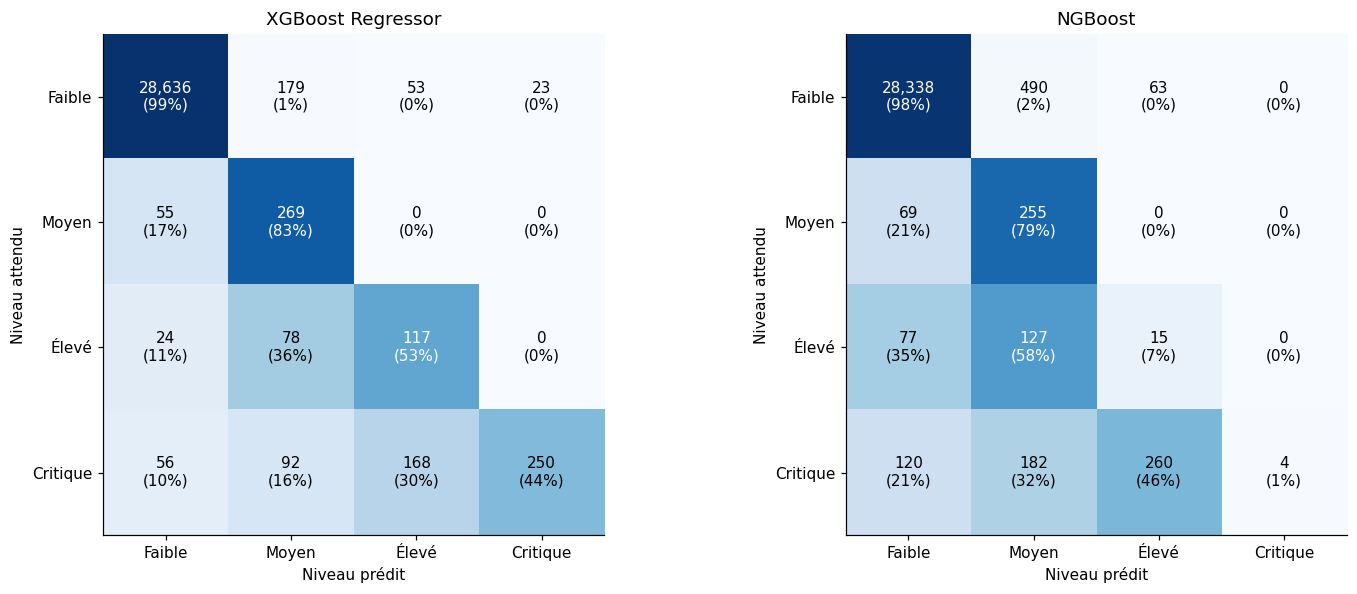

In [ ]:
LEVELS = ["Faible", "Moyen", "Élevé", "Critique"]
BINS = [-0.01, 25, 50, 75, 100.01]
def to_level(values):
    return pd.cut(pd.Series(np.clip(values, 0, 100), index=y_test.index), bins=BINS, labels=LEVELS, right=False)

actual_level, xgb_level, ngb_level = to_level(y_test.to_numpy()), to_level(pred_xgb), to_level(pred_ngb)

level_counts = pd.DataFrame({
    "Attendu": actual_level.value_counts().reindex(LEVELS, fill_value=0),
    "XGBoost": xgb_level.value_counts().reindex(LEVELS, fill_value=0),
    "NGBoost": ngb_level.value_counts().reindex(LEVELS, fill_value=0)})
print("Nombre de flux par niveau :")
display(level_counts)

order = {l: i for i, l in enumerate(LEVELS)}
def level_quality(pred_level):
    gap = (pred_level.map(order).astype(int) - actual_level.map(order).astype(int)).abs()
    return {"Niveau exact": (gap == 0).mean(), "À un niveau près": (gap <= 1).mean()}
print()
print("Qualité de la classification en niveaux :")
display(pd.DataFrame({"XGBoost": level_quality(xgb_level), "NGBoost": level_quality(ngb_level)}).round(4))

# Graphique : matrices de confusion des niveaux
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, lvl) in zip(axes, [("XGBoost Regressor", xgb_level), ("NGBoost", ngb_level)]):
    cm = confusion_matrix(actual_level.astype(str), lvl.astype(str), labels=LEVELS)
    cm_pct = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm_pct[i, j]:.0%})", ha="center", va="center", fontsize=10,
                    color="white" if cm_pct[i, j] > 0.5 else "black")
    ax.set_xticks(range(4)); ax.set_xticklabels(LEVELS); ax.set_yticks(range(4)); ax.set_yticklabels(LEVELS)
    ax.set_xlabel("Niveau prédit"); ax.set_ylabel("Niveau attendu"); ax.set_title(f"{name}"); ax.grid(False)
plt.tight_layout(); plt.show()

### Interprétation des niveaux de risque

Les scores sont classés en quatre niveaux : faible (0 à moins de 25), moyen (25 à moins de 50), élevé (50 à moins de 75) et critique (75 à 100). Le premier tableau compare le nombre de flux par niveau selon le score attendu, XGBoost et NGBoost. Le second donne la part de flux classés dans le bon niveau, et à un niveau près. Dans les matrices, chaque ligne est un niveau réel et les pourcentages sont calculés par ligne : la diagonale représente les flux bien classés. Une erreur « Critique prédit Faible » est la plus grave pour un SOC.

## 12. Variables importantes et conclusion automatique

La criticité est une hypothèse de scénario ; les résultats dépendent de cette table, de l'échantillon et du split. Avant usage dans un SOC, remplacer le mapping par une CMDB validée, vérifier la calibration sur des données ultérieures et faire approuver les seuils par l'équipe opérationnelle.

,Importance XGBoost
categorical__TCP_FLAGS_19,0.2962
categorical__TCP_FLAGS_27,0.0888
categorical__L7_PROTO_13.0,0.0693
remainder__OUT_BYTES,0.0527
remainder__OUT_PKTS,0.0513
categorical__L7_PROTO_2.68,0.0502
categorical__L7_PROTO_3.0,0.0429
remainder__L4_DST_PORT,0.0315
remainder__IN_PKTS,0.0260
remainder__Asset_Criticality,0.0246


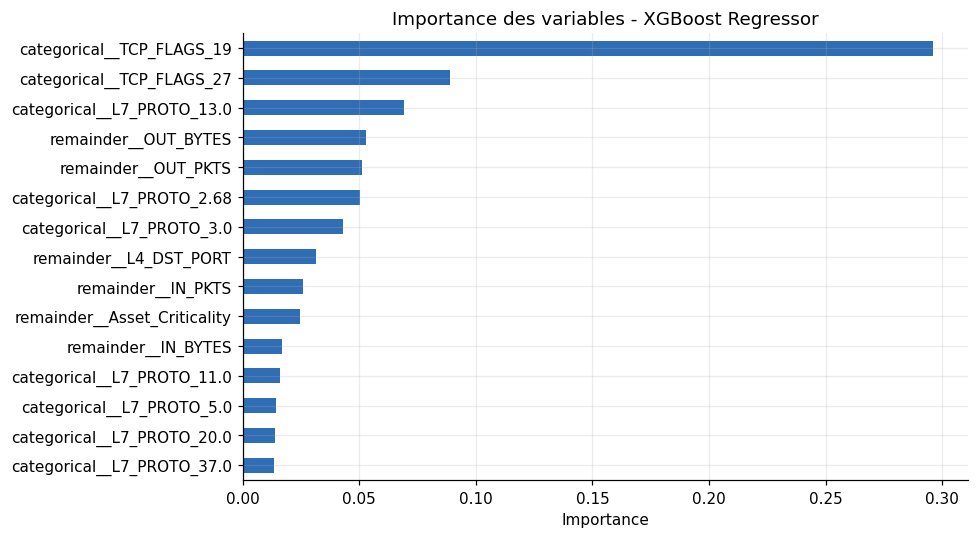

Meilleur MAE  : XGBoost Regressor

Meilleur RMSE : XGBoost Regressor

Meilleur R2   : XGBoost Regressor


In [ ]:
importance = pd.Series(xgb_reg.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)
display(importance.to_frame("Importance XGBoost").round(4))
importance.sort_values().plot(kind="barh", figsize=(9, 5), color=COL_XGB, title="Importance des variables - XGBoost Regressor")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()

print("Meilleur MAE  :", metrics.drop(index="Référence (moyenne)")["MAE"].idxmin())
print()
print("Meilleur RMSE :", metrics.drop(index="Référence (moyenne)")["RMSE"].idxmin())
print()
print("Meilleur R2   :", metrics.drop(index="Référence (moyenne)")["R2"].idxmax())

### Interprétation des variables importantes et conclusion

Le classement indique les caractéristiques les plus utilisées par XGBoost pour ses prédictions. Une importance élevée décrit l'usage par le modèle, pas une cause d'attaque. La conclusion compare les métriques et désigne le meilleur modèle pour cet échantillon et ces paramètres. Il faut aussi vérifier que les deux modèles battent la référence « moyenne ».

**Limites :** un seul découpage, pas de validation croisée, ni réglage des hyperparamètres ; la criticité est hypothétique et définie par l'auteur du scénario ; la loi normale de NGBoost est mal adaptée à une cible concentrée sur 0.

## 13. Stratégie de priorisation des alertes pour un SOC

**Règle proposée (appliquée au score NGBoost, qui fournit aussi l'incertitude) :**

1. **Niveau d'abord** : traiter Critique, puis Élevé, puis Moyen. Les alertes Faibles sont traitées en lot, sans traitement individuel immédiat.
2. **Dans un niveau** : trier par score décroissant, puis par criticité de l'actif décroissante, puis par incertitude décroissante.
3. **Revue humaine obligatoire** si le score est à moins d'un écart-type d'un seuil de niveau (25, 50 ou 75) : le niveau est alors incertain.
4. **Mesure de l'utilité** : on calcule quelle part du risque total est capturée en examinant seulement les X % d'alertes les mieux classées, comparée à un tri aléatoire.

Top 20 des alertes à traiter :


,Destination,Criticité,Score attendu,Score prédit,Incertitude,Niveau,Revue humaine
487095,149.171.126.10,5,100.0,77.57,23.91,Critique,True
745036,149.171.126.11,5,100.0,77.57,17.92,Critique,True
677897,149.171.126.10,5,100.0,75.14,72.57,Critique,True
152521,149.171.126.10,5,100.0,75.04,70.75,Critique,True
967081,149.171.126.12,4,80.0,74.33,23.44,Élevé,True
376282,149.171.126.10,5,100.0,74.00,24.30,Élevé,True
375434,149.171.126.10,5,100.0,74.00,24.30,Élevé,True
374558,149.171.126.10,5,100.0,74.00,24.30,Élevé,True
374301,149.171.126.10,5,100.0,74.00,24.30,Élevé,True
375788,149.171.126.10,5,100.0,74.00,24.30,Élevé,True



Part des alertes nécessitant une revue humaine : 6.4%

Résumé par niveau prédit :


,Alertes,Score_attendu_moyen,Part_attaques_reelles,Revue_humaine
Niveau,,,,
Critique,4,100.000,1.000,1.000
Élevé,338,71.834,0.814,0.997
Moyen,1054,35.863,0.699,0.990
Faible,28604,0.691,0.012,0.019


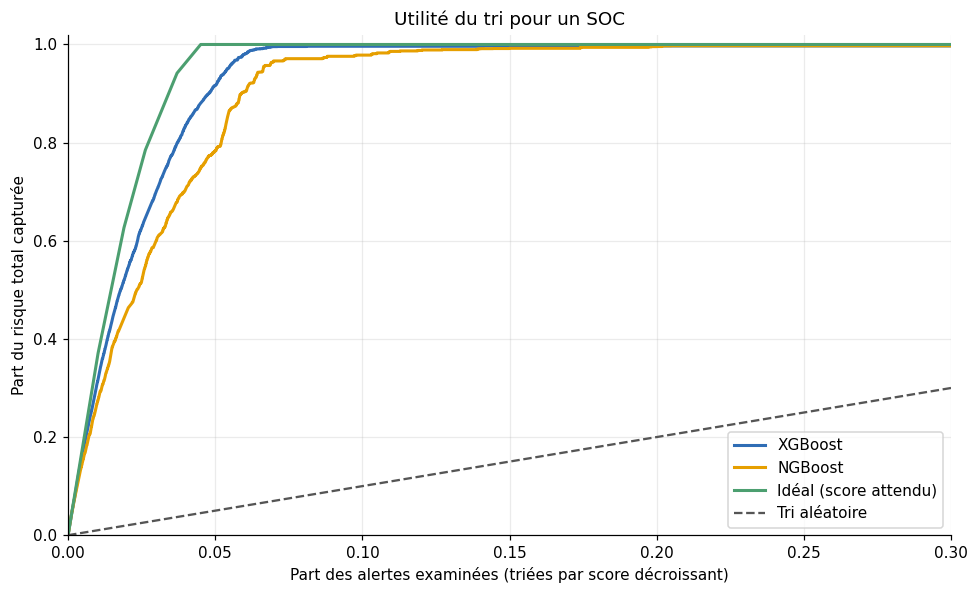

Part du risque total capturée en examinant :


,XGBoost,NGBoost,Tri aléatoire
1% des alertes,0.313,0.273,0.01
5% des alertes,0.916,0.783,0.05
10% des alertes,0.996,0.978,0.10
20% des alertes,0.997,0.996,0.20


In [ ]:
LEVEL_RANK = {"Faible": 1, "Moyen": 2, "Élevé": 3, "Critique": 4}
THRESHOLDS = np.array([25, 50, 75])

soc = pd.DataFrame({
    "Destination": df.loc[y_test.index, "IPV4_DST_ADDR"],
    "Criticité": df.loc[y_test.index, "Asset_Criticality"],
    "Score attendu": y_test,
    "Score prédit": np.round(pred_ngb, 2),
    "Incertitude": np.round(sigma_ngb, 2),
    "Niveau": ngb_level}, index=y_test.index)
soc["rang_niveau"] = soc["Niveau"].map(LEVEL_RANK).astype(int)
dist_to_threshold = np.abs(pred_ngb[:, None] - THRESHOLDS[None, :]).min(axis=1)
soc["Revue humaine"] = dist_to_threshold < sigma_ngb
soc = soc.sort_values(["rang_niveau", "Score prédit", "Criticité", "Incertitude"],
                      ascending=[False, False, False, False])

print("Top 20 des alertes à traiter :")
display(soc.drop(columns="rang_niveau").head(20))
print()
print(f"Part des alertes nécessitant une revue humaine : {soc['Revue humaine'].mean():.1%}")
print()
print("Résumé par niveau prédit :")
summary = soc.groupby("Niveau", observed=False).agg(
    Alertes=("Score prédit", "size"),
    Score_attendu_moyen=("Score attendu", "mean"),
    Part_attaques_reelles=("Score attendu", lambda s: (s > 0).mean()),
    Revue_humaine=("Revue humaine", "mean")).reindex(LEVELS[::-1])
display(summary.round(3))

# Graphique : part du risque total capturée selon la part d'alertes examinées
actual_risk = y_test.to_numpy(); total_risk = actual_risk.sum(); n = len(actual_risk)
def gain_curve(score):
    idx = np.argsort(-np.asarray(score), kind="stable")
    return np.arange(1, n + 1) / n, np.cumsum(actual_risk[idx]) / total_risk

fig, ax = plt.subplots(figsize=(9, 5.5))
for name, s, col in [("XGBoost", pred_xgb, COL_XGB), ("NGBoost", pred_ngb, COL_NGB), ("Idéal (score attendu)", actual_risk, "#4C9F70")]:
    xs, ys = gain_curve(s)
    ax.plot(xs, ys, label=name, color=col, lw=2)
ax.plot([0, 1], [0, 1], "--", color=COL_REF, label="Tri aléatoire")
ax.set_xlim(0, 0.3); ax.set_ylim(0, 1.02)
ax.set_xlabel("Part des alertes examinées (triées par score décroissant)")
ax.set_ylabel("Part du risque total capturée")
ax.set_title("Utilité du tri pour un SOC"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

print("Part du risque total capturée en examinant :")
rows = {}
for frac in [0.01, 0.05, 0.10, 0.20]:
    k = max(int(frac * n), 1)
    rows[f"{frac:.0%} des alertes"] = {
        "XGBoost": gain_curve(pred_xgb)[1][k - 1], "NGBoost": gain_curve(pred_ngb)[1][k - 1], "Tri aléatoire": frac}
display(pd.DataFrame(rows).T.round(3))

### Interprétation de la stratégie SOC

Le tableau « Top 20 » montre les alertes à traiter en premier : niveau critique, score élevé, actif important, incertitude haute en cas d'égalité. La colonne « Revue humaine » signale les alertes dont le niveau peut basculer d'un seuil à l'autre : un analyste doit les confirmer.

Le résumé par niveau donne la part d'attaques réelles dans chaque niveau prédit : il indique si le niveau « critique » mérite vraiment un traitement immédiat. Le graphique et le dernier tableau montrent la part du risque total capturée en n'examinant que les premières alertes : plus la courbe est proche de la courbe idéale et éloignée de la diagonale (tri aléatoire), plus le tri est utile. Avec une capacité d'analyse limitée, c'est ce critère qui compte le plus pour un SOC.

**Avant usage opérationnel :** remplacer la criticité par une CMDB validée, recalibrer les seuils avec l'équipe SOC et vérifier le tri sur des données plus récentes.